<img src='http://www-scf.usc.edu/~ghasemig/images/sharif.png' alt="SUT logo" width=500 height=300 align=center class="saturate" >

<br>
<font>
<div dir=ltr align=center>
<font color=0F5298 size=7>
    Intelligent Analysis of Biomedical Images <br>
<font color=2565AE size=5>
    Computer Engineering Department <br>
    Fall 2025<br>
<font color=3C99D size=5>
    Practical Assignment 2 - From Sinograms to CT Images <br>
<font color=696880 size=4>
Alireza Malekhosseini


**NAME:** Kian Tarakemeh

**STUDENT NUMBER:** 401110404


# From Sinograms to CT Images + A Tiny DL Denoiser (100 + 5)
In this notebook You will implement:
1) Synthetic dataset of 1,000 randomized 128×128 phantoms (Shepp–Logan + ellipses)  
2) From-scratch Radon (forward) and FBP (filters: ramp, shepp-logan, hann)  
3) Low-dose Poisson noise & limited-angle experiments  
4) Metrics: PSNR, SSIM  
5) Tiny U-Net-lite denoiser (supervised L1/L2) trained on (FBP-noisy → Ground-truth)



In [ ]:
!pip install scikit-image torch torchvision matplotlib tqdm

In [2]:

import math, random, os, time
from dataclasses import dataclass
from typing import Tuple

import numpy as np
import matplotlib.pyplot as plt

from skimage.data import shepp_logan_phantom
from skimage.transform import radon as sk_radon, iradon as sk_iradon, rotate
from skimage.metrics import peak_signal_noise_ratio as psnr, structural_similarity as ssim
import skimage.transform as skt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device


device(type='cuda')

## 0) Reproducibility & Config (0 pts)

In [3]:

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic=True
    torch.backends.cudnn.benchmark=False
set_seed(42)

# You can change
@dataclass
class CFG:
    img_size: int = 128
    n_train: int = 800
    n_val: int = 100
    n_test: int = 100
    angles_180: int = 180
    limited_deg: int = 120
    I0: float = 1e4
    eps: float = 1e-8
CFG = CFG(); CFG


CFG(img_size=128, n_train=800, n_val=100, n_test=100, angles_180=180, limited_deg=120, I0=10000.0, eps=1e-08)


## 1) Synthetic Dataset: Shepp–Logan + Random Ellipses (15 pts)

**Task:** generate a dataset of 1,000 phantoms. Visualize a grid to confirm variety.

---
**Question:** In CT imaging research,  we use mathematical phantoms like Shepp-Logan instead of real patient data for developing and testing reconstruction algorithms. What is the reason for this? Discuss both the advantages and limitations of this approach, and explain how synthetic data generation impact the eventual real-world deployment of AI systems in healthcare?.

**Answer:**
In research, we use mathematical phantoms because they provide a perfect **"Ground Truth."** In real patient scans, we never know exactly what the perfect, noise-free image should look like. With a phantom, we know the exact mathematical value of every pixel.

*   **Advantages:**
    *   **Exact Reference:** You can measure error precisely because the original image is known perfectly.
    *   **Controlled Testing:** You can simulate difficult situations (like low radiation dose or limited angles) safely without risking patients.
    *   **No Privacy Issues:** No patient data, consent forms, or ethics approval are needed.
*   **Limitations:**
    *   **Too Simple:** Phantoms are usually made of simple geometric shapes (ellipses). They lack the complex textures, organ variations, and subtle biological details of real human anatomy.
*   **Impact on AI Deployment:**
    * If an AI is trained only on synthetic data, it may fail in the real world. This is known as **"Domain Shift."** The AI learns to reconstruct simple shapes perfectly but gets confused by the complexity and "messiness" of real human tissues. Successful deployment requires validating the model on real clinical data to ensure it handles real-world noise correctly.

---

**Question:** First Explain about PSNR and its formulation.

**Answer:**
**PSNR (Peak Signal-to-Noise Ratio)** is a standard metric used to measure the reconstruction quality of an image compared to the original ideal image.

*   **What it tells us:** It measures the ratio between the maximum possible power of a signal (the image info) and the power of the corrupting noise (the error). A **higher PSNR value** (measured in decibels/dB) indicates better image quality and less error.
*   **The Formulation:**
It is calculated based on the Mean Squared Error (MSE).

$$
PSNR = 10 \cdot \log_{10} \left( \frac{MAX_I^2}{MSE} \right)
$$

*   **$MAX_I$**: The maximum possible pixel value of the image (e.g., 255 for an 8-bit image).
*   **$MSE$**: The average squared difference between the reconstructed image and the original image.

---

**Question:** If an algorithm achieves 40 dB PSNR on Shepp-Logan phantoms but only 30 dB on real patient data, is it clinically useful?

**Answer:**
**Not necessarily.** While 30 dB is generally considered a decent score, the PSNR number alone does not guarantee that the image is useful for a doctor.

1.  **Why the drop?** It is expected that performance drops on real data because real anatomy is far more complex and unstructured than a geometric phantom.
2.  **The "Clinical Utility" Gap:**
    *   **PSNR vs. Diagnosis:** An algorithm might smooth out the image to reduce noise (which improves the PSNR score) but in doing so, it might **blur out a small tumor** or a fine fracture. This makes the image clinically useless, despite the score.
    *   Conversely, an image might have more background noise (lower PSNR) but perfectly **preserve the sharp edges** of a lesion, making it highly useful for diagnosis.
3.  **Conclusion:** An algorithm is only clinically useful if it preserves **diagnostic features** (edges, contrast, texture). This must be verified by radiologists, not just by a mathematical calculation.

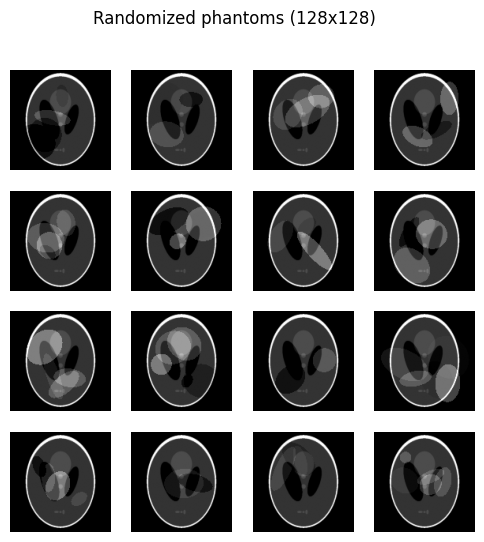

In [4]:

def draw_ellipse(img, cy, cx, ay, ax, theta, val):
    """ draws ellipses with desired size and position"""
    H, W = img.shape
    y, x = np.ogrid[:H, :W]
    yt = (y - cy); xt = (x - cx)
    c, s = np.cos(theta), np.sin(theta)
    xr =  (xt*c + yt*s)
    yr = (-xt*s + yt*c)
    mask = (xr*xr)/(ax*ax + 1e-8) + (yr*yr)/(ay*ay + 1e-8) <= 1.0
    img[mask] += val

def make_random_phantom(size=128, n_extra=3):
    """makes random phantoms"""
    #TODO: First, generate a 2D Shepp-Logan phantom as a NumPy array of floats.
    #Then, resize it to the desired size × size using interpolation while keeping the values between 0 and 1.
    base = shepp_logan_phantom()
    phantom = skt.resize(base, (size, size), mode='constant', anti_aliasing=True).astype(np.float32)


    for _ in range(n_extra):
        cy = np.random.uniform(0.25*size, 0.75*size)
        cx = np.random.uniform(0.25*size, 0.75*size)
        ay = np.random.uniform(0.05*size, 0.2*size)
        ax = np.random.uniform(0.05*size, 0.25*size)
        theta = np.random.uniform(0, np.pi)
        val = np.random.uniform(-0.15, 0.3)
        draw_ellipse(phantom, cy, cx, ay, ax, theta, val)
    phantom = np.clip(phantom, 0.0, 1.0)
    return phantom

# Visualize
imgs = [make_random_phantom(CFG.img_size, n_extra=np.random.randint(2,6)) for _ in range(16)]
fig, axes = plt.subplots(4,4, figsize=(6,6))
for ax, im in zip(axes.ravel(), imgs):
    ax.imshow(im, cmap='gray'); ax.axis('off')
plt.suptitle("Randomized phantoms (128x128)"); plt.show()

## Radon Transform — Theory & CT Motivation

The **Radon Transform** converts a 2D object $ f(x,y) $ into a set of **1D line integrals** taken at different angles.  
Each integral represents X-ray attenuation measured by a detector as rays pass through the object:

$$
R f(\theta, s) = \int_{-\infty}^{+\infty} f(x,y)\, \mathrm{d}l
$$

where:
- $ \theta $ = projection angle
- $ s $ = detector position perpendicular to each projection line

The collection of all projections vs. angle forms a **sinogram**, the raw data acquired in CT scanners.

---

X-ray CT systems measure how much radiation is absorbed along each ray path.  
These are **exactly** Radon line integrals.  
Thus, reconstructing the image means **inverting** the Radon transform.

$$
f(x,y) = R^{-1}\{ \text{sinogram} \}
$$


Understanding forwards (projection) and backwards (reconstruction) operations is essential for improving CT quality, reducing radiation dose, and developing modern iterative / deep-learning-based reconstruction methods.




### Fourier Slice Theorem

**Question:** Read about Fourier Slice Theorem. How does the Radon transform relate each projection to the 2D Fourier Transform of the image?

**Answer:**
The **Fourier Slice Theorem** (also called the Central Slice Theorem) acts as a bridge connecting the raw data (projections) to the frequency information of the image.

simple relationship:

1.  **The Projection:** Start with the Radon transform of an image at a specific angle $\theta$. This gives you a 1D signal (the projection profile).
2.  **1D Fourier Transform:** Take the **1D Fourier Transform** of that projection.
3.  **The Connection:** The result of that 1D transform is exactly equal to a **"slice"** (a straight line) through the **2D Fourier Transform** of the original image. This slice passes through the center (origin) of the 2D frequency domain at the same angle $\theta$.

**Mathematically:**
If $P_\theta(t)$ is the projection at angle $\theta$, and $F(u,v)$ is the 2D Fourier transform of the image:

$$ \mathcal{F}_{1D} \{ P_\theta(t) \} = \text{Slice of } F(u,v) \text{ at angle } \theta $$

It tells us that if we take projections from all angles (0 to 180 degrees) and Fourier transform them, we can fill up the entire 2D frequency space of the object. Once the 2D space is filled, we can simply do an Inverse 2D Fourier Transform to reconstruct the final image.



## 2) From-scratch Radon (Forward Projection) (10 pts)
This cell implements a naive Radon transform: the image is rotated by each projection angle θ and the values along its columns are summed to form one projection line in the sinogram. By repeating this over many angles, we build a full sinogram that represents how the object would be measured by a CT scanner.

→ You will then compare your simple implementation to skimage.radon to observe differences due to interpolation, padding, and assumptions about the circular support.


Simple shape: (128, 180)
Skimage shape: (128, 180)


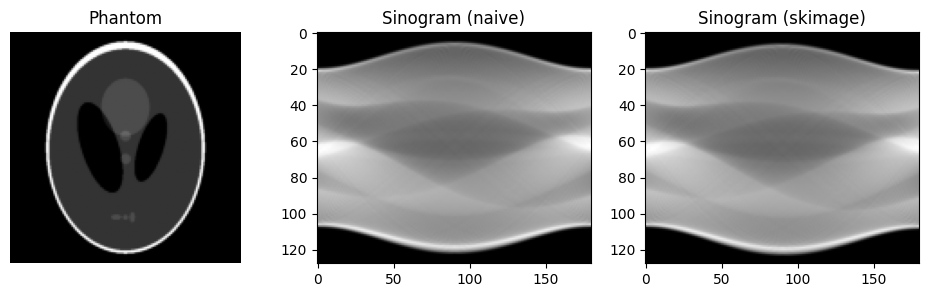

Mean abs diff naive vs skimage: 0.5873659074024725


In [5]:
def radon_simple(img: np.ndarray, angles_rad: np.ndarray) -> np.ndarray:
    """Computes a sinogram by rotating the image to each given angle and
    summing the pixel values along one axis.
    Collect all projections into a 2D array."""
    angles_deg = np.rad2deg(angles_rad)

    num_angles = len(angles_rad)
    projection_length = img.shape[0]
    sino = np.zeros((projection_length, num_angles))

    for i, angle in enumerate(angles_deg):
        rotated = skt.rotate(img, -angle, resize=False, preserve_range=True)
        sino[:, i] = np.sum(rotated, axis=0)

    return sino


phantom = shepp_logan_phantom()
phantom = skt.resize(phantom, (128, 128), anti_aliasing=True)
angles_full = np.linspace(0, np.pi, 180, endpoint=False)
angles_deg = np.rad2deg(angles_full)
sino_naive = radon_simple(phantom, angles_full)
sino_ski = skt.radon(phantom, theta=angles_deg, circle=True)

print(f"Simple shape: {sino_naive.shape}")
print(f"Skimage shape: {sino_ski.shape}")


fig, axs = plt.subplots(1,3, figsize=(12,3))
axs[0].imshow(phantom, cmap='gray'); axs[0].set_title("Phantom"); axs[0].axis('off')
axs[1].imshow(sino_naive, cmap='gray', aspect='auto'); axs[1].set_title("Sinogram (naive)")
axs[2].imshow(sino_ski,   cmap='gray', aspect='auto'); axs[2].set_title("Sinogram (skimage)")
plt.show()

print("Mean abs diff naive vs skimage:", float(np.abs(sino_naive - sino_ski).mean()))


Simple shape: (128, 180)
Skimage shape: (128, 180)


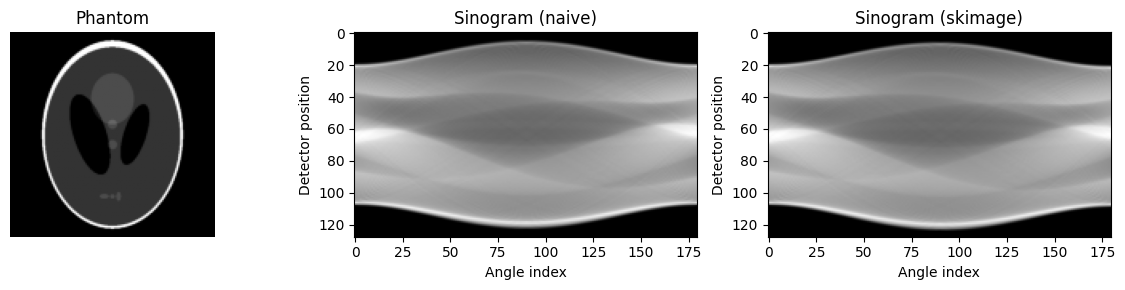

Mean abs diff naive vs skimage: 0.5873659074024725


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.transform import radon, rotate
from skimage.data import shepp_logan_phantom



print(f"Simple shape: {sino_naive.shape}")
print(f"Skimage shape: {sino_ski.shape}")

# Visualization
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
axs[0].imshow(phantom, cmap='gray')
axs[0].set_title("Phantom")
axs[0].axis('off')

axs[1].imshow(sino_naive, cmap='gray', aspect='auto')
axs[1].set_title("Sinogram (naive)")
axs[1].set_xlabel("Angle index")
axs[1].set_ylabel("Detector position")

axs[2].imshow(sino_ski, cmap='gray', aspect='auto')
axs[2].set_title("Sinogram (skimage)")
axs[2].set_xlabel("Angle index")
axs[2].set_ylabel("Detector position")

plt.tight_layout()
plt.show()

print("Mean abs diff naive vs skimage:", float(np.abs(sino_naive - sino_ski).mean()))



## 3) Low-dose Poisson Noise & Limited-angle (10 pts)

We convert line integrals $p$ to counts: $I=I_0 e^{-p}$, sample Poisson, then invert: $\tilde{p}=-\log(\tilde{I}/I_0)$.


This cell simulates realistic CT data by adding **Poisson (photon) noise** to the sinogram. In X-ray CT, detectors measure photon counts $I$, not line-integral values directly. So we convert each projection value $p$ into expected counts using the exponential attenuation model (Beer–Lambert law):

$$ I = I_0 e^{-p} $$

Then, to imitate low-dose CT, we draw noisy photon counts from a Poisson distribution (since X-ray photons arrive as discrete random events), and convert the noisy counts back into projection space:

$$ \tilde{p} = -\log\left(\frac{\tilde{I}}{I_0}\right) $$

A correct implementation must handle:
- Normalizing the sinogram before applying noise
- Avoiding $\log(0)$ by clamping counts to a minimum value
- Preserving the overall structure of the projections

Clean sinogram
  Min: 0.000, Max: 32.915
  Mean: 15.769, Std: 8.374
shape of sino clean:  (128, 180)
shape of sino_noisy:  (128, 180)
shape of sino_limited:  (128, 120)


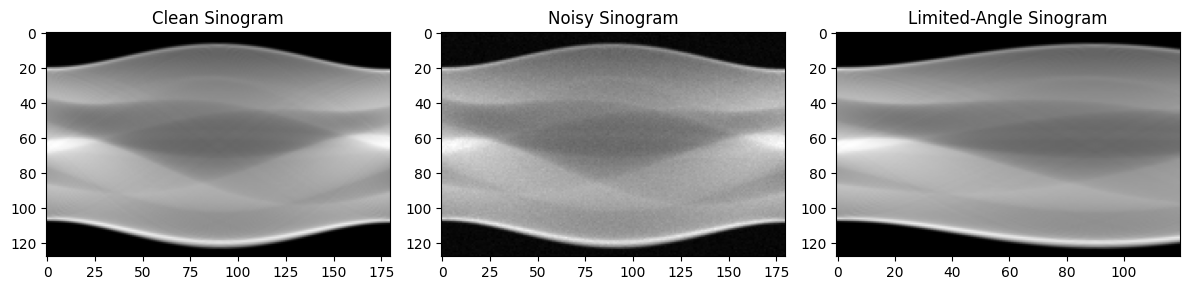

In [7]:

def add_poisson_noise_to_sinogram(sino: np.ndarray, I0=1e4, eps=1e-8) -> np.ndarray:
    """applies Poisson noise to the imagegiven the description above"""
    transmission = np.exp(-sino / sino.max())
    photon_counts = I0 * transmission
    noisy_counts = np.random.poisson(photon_counts)
    noisy_counts = np.maximum(noisy_counts, eps)
    sino_noisy = -np.log(noisy_counts / I0)
    sino_noisy = sino_noisy * sino.max() / sino_noisy.max()
    return sino_noisy


phantom = shepp_logan_phantom()
phantom = skt.resize(phantom, (128, 128))

angles_lim = np.linspace(0, np.pi, 180, endpoint=False)
sino_clean = skt.radon(phantom, theta=np.rad2deg(angles_lim), circle=True)

print("Clean sinogram")
print(f"  Min: {sino_clean.min():.3f}, Max: {sino_clean.max():.3f}")
print(f"  Mean: {sino_clean.mean():.3f}, Std: {sino_clean.std():.3f}")
print(f"shape of sino clean:  {sino_clean.shape}")

I0 = 1e4
sino_noisy = add_poisson_noise_to_sinogram(sino_clean, I0=I0)
print(f"shape of sino_noisy:  {sino_noisy.shape}")

angles_limited = np.linspace(0, 2*np.pi/3, 120, endpoint=False)
sino_limited = skt.radon(phantom, theta=np.rad2deg(angles_limited), circle=True)
print(f"shape of sino_limited:  {sino_limited.shape}")

fig, axs = plt.subplots(1, 3, figsize=(12, 3))
axs[0].imshow(sino_clean, cmap='gray', aspect='auto')
axs[0].set_title("Clean Sinogram")
axs[1].imshow(sino_noisy, cmap='gray', aspect='auto')
axs[1].set_title("Noisy Sinogram")
axs[2].imshow(sino_limited, cmap='gray', aspect='auto')
axs[2].set_title("Limited-Angle Sinogram")
plt.tight_layout()
plt.show()

**Question:** Why does increasing $I_0$ (the number of input photons) reduce noise in CT measurements, while increasing the maximum $p$ value (stronger attenuation) increases noise?

**Answer:**

This behavior is governed by **Poisson statistics**, which describes the counting of photons.

**1. Why increasing $I_0$ reduces noise:**
X-ray detection is a counting process. The noise in counting photons is equal to the square root of the count ($\sqrt{N}$).
*   **Signal-to-Noise Ratio (SNR):** The quality of the signal is determined by the ratio of the signal ($N$) to the noise ($\sqrt{N}$).
  $$SNR = \frac{N}{\sqrt{N}} = \sqrt{N}$$
*   **Result:** If you increase $I_0$ (input photons), the number of detected photons ($N$) increases. Since SNR is proportional to $\sqrt{N}$, increasing the count makes the relative noise smaller and the image clearer.

**2. Why increasing attenuation ($p$) increases noise:**
*   **The mechanism:** A higher $p$ value (like dense bone or metal) means the object is blocking more X-rays. This results in **fewer photons** reaching the detector on the other side.
*   **The problem:** When fewer photons are detected (low $N$), the relative uncertainty (noise) becomes very large.
    *   For example, if only 10 photons get through, the random variation is significant compared to the signal.
*   **Result:** This leads to "photon starvation," causing streaks and high noise in dense areas of the image.

**Summary:**
*   **More photons ($I_0 \uparrow$)** $\rightarrow$ Better statistics $\rightarrow$ **Less Noise.**
*   **More blocking ($p \uparrow$)** $\rightarrow$ Fewer detected photons $\rightarrow$ **More Noise.**


## 4) FBP: Filters & Backprojection (25 pts)

Filtered Backprojection is the classical and most widely used method for CT image reconstruction. It has two main steps:

---

### 1 Frequency-Domain Filtering

Each projection (row of the sinogram) is first transformed into the frequency domain using the 1D Fourier Transform.  

The ideal inverse Radon solution requires multiplying by a **ramp filter**:

$$ H_{\text{ramp}}(f) = |f| $$

This corrects the low-frequency bias introduced by plain backprojection and emphasizes high frequencies (edges).  
However, ramp filtering can amplify noise — so we often apply **windowed variants**:

- **Shepp–Logan**: ramp × sinc → soft high-frequency reduction  
- **Hann**: ramp × Hann window → stronger noise suppression  

After filtering in frequency space, we invert back to the spatial domain to get filtered projections.

---

### 2 Backprojection

Each filtered projection is then **smeared back** into the image at its corresponding angle:

- For angle $\theta$, copy the projection across the image as parallel lines
- Rotate this “smear” back by $\theta$
- Sum contributions from all angles

Finally, we normalize by a constant factor to correctly scale the reconstructed values.


FBP implements the **Fourier Slice Theorem** in practice:  
filtering recovers the correct frequency balance, and backprojection collects the slices to form the full 2D image.



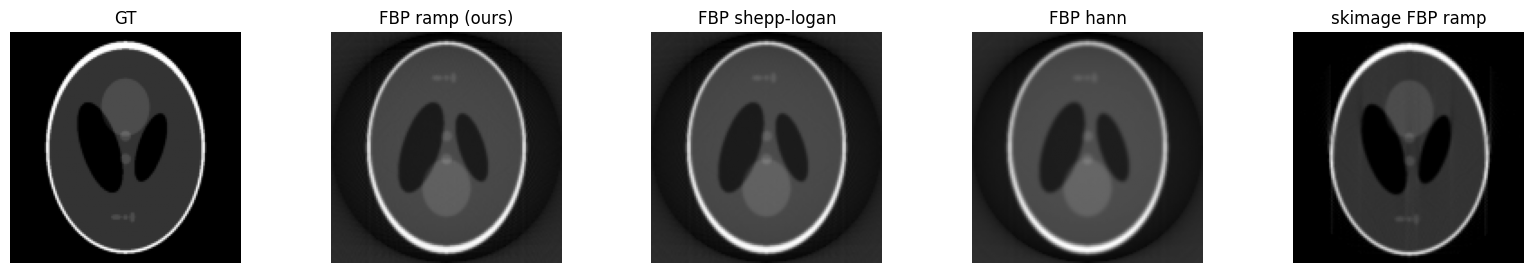

ours ramp PSNR: 16.53197950388238 SSIM: 0.3575641928391182
ours shepp-logan PSNR: 16.432631531469116 SSIM: 0.3553766136357401
ours hann PSNR: 15.942133304413364 SSIM: 0.3413701432693094
skimage ramp PSNR: 19.59440973317139 SSIM: 0.8201880965051033


In [8]:
def fbp_filter(n_det: int, filter_name: str = 'ramp'):
    freqs = np.fft.fftfreq(n_det).astype(np.float32)
    absf  = np.abs(freqs)
    ramp  = absf

    fmax = absf.max() + 1e-8

    if filter_name == 'ramp':
        H = ramp

    elif filter_name == 'shepp-logan':
        H = ramp * np.sinc(freqs / (2.0 * fmax))
        H[0] = 0.0

    elif filter_name == 'hann':
        w = np.zeros_like(freqs)
        mask = absf <= fmax
        w[mask] = 0.5 + 0.5 * np.cos(np.pi * absf[mask] / fmax)
        H = ramp * w

    else:
        raise ValueError(f"Unknown filter '{filter_name}'.")

    return H.astype(np.float32)


def fbp_reconstruct(sino: np.ndarray, angles: np.ndarray,
                    filter_name='ramp', output_size=128) -> np.ndarray:

    n_det, n_ang = sino.shape

    H = fbp_filter(n_det, filter_name)[:, None]
    sino_fft  = np.fft.fft(sino, axis=0)
    sino_filt = np.fft.ifft(sino_fft * H, axis=0).real.astype(np.float32)

    half = (output_size - 1) / 2.0
    x = np.linspace(-half, half, output_size)
    y = np.linspace(-half, half, output_size)
    xx, yy = np.meshgrid(x, y)

    recon = np.zeros((output_size, output_size), dtype=np.float32)

    det_pos = np.linspace(-half, half, n_det)

    for i, theta in enumerate(angles):
        proj = sino_filt[:, i]
        s = xx * np.cos(theta) + yy * np.sin(theta)
        vals = np.interp(s.ravel(), det_pos, proj, left=0.0, right=0.0)
        recon += vals.reshape(output_size, output_size)

    recon *= np.pi / (2.0 * len(angles))
    recon -= recon.min()
    m = recon.max()
    if m > 0:
        recon /= m

    return recon


angles_lim = np.linspace(0.0, np.deg2rad(CFG.limited_deg), CFG.limited_deg, endpoint=False)
angles_full = np.linspace(0.0, np.pi, CFG.angles_180, endpoint=False)

sino_clean = radon_simple(phantom, angles_full)

fbp_ramp = fbp_reconstruct(sino_clean, angles_full, filter_name='ramp', output_size=CFG.img_size)
fbp_sl   = fbp_reconstruct(sino_clean, angles_full, filter_name='shepp-logan', output_size=CFG.img_size)
fbp_hann = fbp_reconstruct(sino_clean, angles_full, filter_name='hann', output_size=CFG.img_size)

fbp_sk = skt.iradon(sino_clean, theta=np.rad2deg(angles_full), filter_name='ramp', circle=True)
fbp_sk = np.clip(fbp_sk, 0.0, 1.0)


def show_row(row, titles):
    fig,axs=plt.subplots(1,len(row), figsize=(4*len(row),3))
    for ax,im,t in zip(axs,row,titles):
        ax.imshow(im, cmap='gray'); ax.set_title(t); ax.axis('off')
    plt.show()

show_row([phantom, fbp_ramp, fbp_sl, fbp_hann, fbp_sk],
         ["GT","FBP ramp (ours)","FBP shepp-logan","FBP hann","skimage FBP ramp"])

for name, rec in [("ours ramp", fbp_ramp), ("ours shepp-logan", fbp_sl),
                  ("ours hann", fbp_hann), ("skimage ramp", fbp_sk)]:
    print(name, "PSNR:", psnr(phantom, rec, data_range=1.0), "SSIM:", ssim(phantom, rec, data_range=1.0))

**Question:** Why does the ramp filter sharpen edges but also make the reconstruction more sensitive to noise?

**answer:**
The behavior of the ramp filter comes from how it treats different frequencies in the image data.

**1. Why it sharpens edges (High-Frequency Boosting):**
*   In frequency analysis, **edges and fine details** correspond to **high frequencies**.
*   The ramp filter is designed to amplify high frequencies linearly (it looks like a "V" shape in the frequency domain).
*   By boosting these high frequencies, the filter counteracts the natural blurring that happens during the back-projection process. This restores the sharpness of boundaries and fine structures.

**2. Why it increases noise sensitivity:**
*   **Noise** (random variations in pixel values) also exists primarily in the **high-frequency** range.
*   The ramp filter is "blind" to the difference between "good" high frequencies (edges) and "bad" high frequencies (noise). It amplifies **everything** at the high end of the spectrum.
*   **Result:** While the edges get sharper, the background graininess (noise) gets much louder and more visible.

**Analogy:**
Imagine an audio equalizer. If you turn the "Treble" (high frequency) knob all the way up to hear the crisp sound of a cymbal (the edge), you will also hear a lot of background hiss and static (the noise). The ramp filter is like turning the Treble knob to the maximum.

Apply fbp filter with a limited degree to see the results.

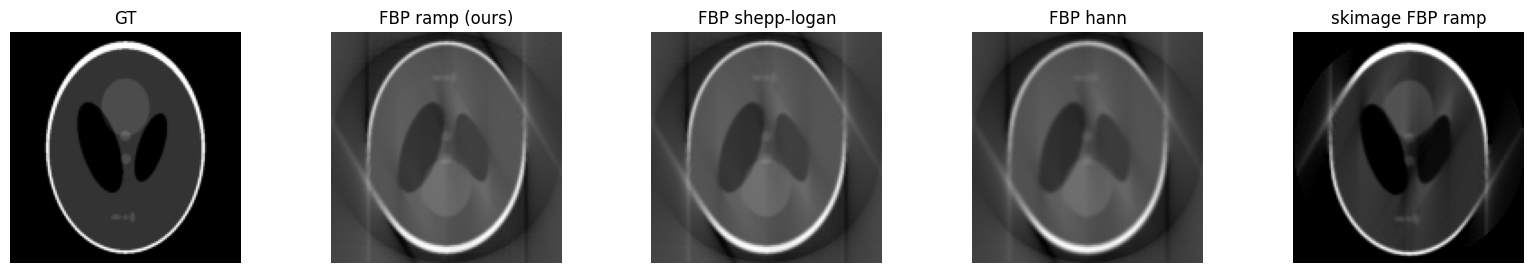

ours ramp PSNR: 12.951246021985895 SSIM: 0.2953938179759555
ours shepp-logan PSNR: 13.015222087416273 SSIM: 0.2952518978697628
ours hann PSNR: 13.323290018839264 SSIM: 0.29253110157899986
skimage ramp PSNR: 18.68811468782554 SSIM: 0.6650514071517449


In [9]:
CFG.limited_deg = 150

sino_full = radon_simple(phantom, np.linspace(0.0, np.pi, CFG.angles_180, endpoint=False))
sino_lim  = radon_simple(phantom, np.linspace(0.0, np.deg2rad(CFG.limited_deg), CFG.limited_deg, endpoint=False))
angles_full = np.linspace(0.0, np.pi, CFG.angles_180, endpoint=False)
angles_lim  = np.linspace(0.0, np.deg2rad(CFG.limited_deg), CFG.limited_deg, endpoint=False)

fbp_ramp = fbp_reconstruct(sino_lim, angles_lim, filter_name='ramp', output_size=CFG.img_size)
fbp_sl   = fbp_reconstruct(sino_lim, angles_lim, filter_name='shepp-logan', output_size=CFG.img_size)
fbp_hann = fbp_reconstruct(sino_lim, angles_lim, filter_name='hann', output_size=CFG.img_size)

fbp_sk = sk_iradon(sino_lim, theta=np.rad2deg(angles_lim), filter_name='ramp', circle=True)
fbp_sk = np.clip(fbp_sk, 0.0, 1.0)

def show_row(row, titles):
    fig,axs=plt.subplots(1,len(row), figsize=(4*len(row),3))
    for ax,im,t in zip(axs,row,titles):
        ax.imshow(im, cmap='gray'); ax.set_title(t); ax.axis('off')
    plt.show()

show_row([phantom, fbp_ramp, fbp_sl, fbp_hann, fbp_sk],
         ["GT","FBP ramp (ours)","FBP shepp-logan","FBP hann","skimage FBP ramp"])

for name, rec in [("ours ramp", fbp_ramp),
                  ("ours shepp-logan", fbp_sl),
                  ("ours hann", fbp_hann),
                  ("skimage ramp", fbp_sk)]:
    print(name, "PSNR:", psnr(phantom, rec, data_range=1.0), "SSIM:", ssim(phantom, rec, data_range=1.0))


# part 2: denoising

## 5) Making a Dataset for Denoising: (FBP_noisy → GT) (5 pts)

We generate (input, target) pairs with **60 views**.  
**Input:** FBP of Poisson-noisy sinogram. **Target:** ground-truth phantom.


In [46]:
def make_dataset(n_samples, img_size, angles, I0, filt='ramp'):
    X=[]; Y=[]
    for _ in range(n_samples):
        ph = make_random_phantom(img_size, n_extra=np.random.randint(2,6))
        sino = radon_simple(ph, angles)
        sino_noisy = add_poisson_noise_to_sinogram(sino, I0=I0, eps=CFG.eps)
        rec = fbp_reconstruct(sino_noisy, angles, filter_name=filt, output_size=img_size)


        # Store
        X.append(rec[np.newaxis, ...].astype(np.float32))
        Y.append(ph[np.newaxis, ...].astype(np.float32))


    return np.stack(X), np.stack(Y)


n_train, n_val, n_test = 800, 100, 100

limited_angle = 180
angles_lim = np.linspace(0, math.radians(limited_angle), CFG.angles_180 * limited_angle // 180, endpoint=False)

Xtr, Ytr = make_dataset(n_train, CFG.img_size, angles_lim, CFG.I0, 'ramp')
Xva, Yva = make_dataset(n_val, CFG.img_size, angles_lim, CFG.I0, 'ramp')
Xte, Yte = make_dataset(n_test, CFG.img_size, angles_lim, CFG.I0, 'ramp')

Xtr.shape, Ytr.shape


((800, 1, 128, 128), (800, 1, 128, 128))

### 5.1 Visualize a random training triplet

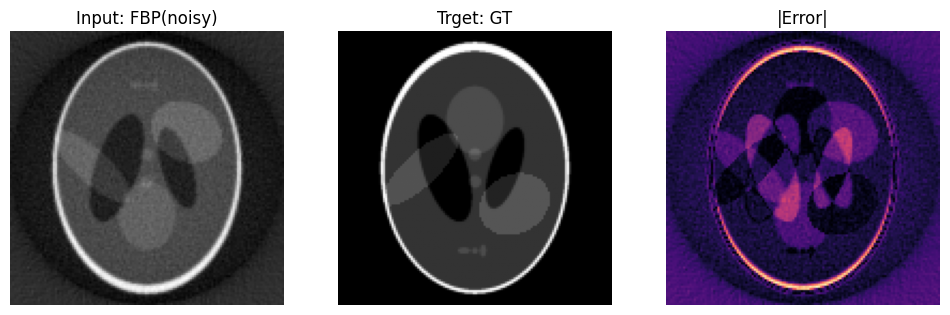

In [47]:
def show_triplet(X, Y, idx=None):
    """Visualize a single sample from the dataset by displaying three images side by side:
    the input (FBP reconstruction with noise), the target ground truth phantom, and the absolute error between them.
    idx is the sample index in the dataset"""
    if idx is None:
        idx = np.random.randint(0, len(X))

    x = X[idx][0]
    y = Y[idx][0]
    err = np.abs(x - y)

    fig, axs = plt.subplots(1, 3, figsize=(12, 4))
    axs[0].imshow(x, cmap='gray'); axs[0].set_title("Input: FBP(noisy)"); axs[0].axis('off')
    axs[1].imshow(y, cmap='gray'); axs[1].set_title("Trget: GT"); axs[1].axis('off')
    axs[2].imshow(err, cmap='magma'); axs[2].set_title("|Error|"); axs[2].axis('off')
    plt.show()


show_triplet(Xtr, Ytr)


## 6) Torch DataLoaders (5 pts)


In [48]:
class PairDataset(Dataset):
    """Create a PyTorch dataset class that wraps paired NumPy arrays X (inputs) and Y (targets).
    Implement __len__ and __getitem__"""
    def __init__(self, X, Y):
        self.X = torch.from_numpy(X).float()
        self.Y = torch.from_numpy(Y).float()

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, i):
        return self.X[i], self.Y[i]

train_ds = PairDataset(Xtr, Ytr)
val_ds = PairDataset(Xva, Yva)
test_ds = PairDataset(Xte, Yte)

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=16, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=16, shuffle=False)

len(train_ds), len(val_ds), len(test_ds)


(800, 100, 100)


## 7) Tiny U-Net-lite Denoiser (Supervised L1/L2) (20 pts)

**Input:** 1×128×128 noisy-FBP  
**Output:** 1×128×128 denoised  
We'll train with **L1** and **L2**.


In [ ]:
class DoubleConv(nn.Module):
    """Implement a building block with two consecutive convolutional layers,
    each followed by batch normalization and ReLU activation.
    This block preserves spatial size while increasing feature channels"""
    def __init__(self,in_ch,out_ch):
        super().__init__()
        #TODO
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )
    def forward(self,x):
        return self.net(x)

class UNetLite(nn.Module):
    def __init__(self, base=48):
        """Implement a lightweight U-Net for image-to-image reconstruction:
        first, create downsampling blocks using DoubleConv and max-pooling to extract hierarchical features;
        then apply a bottleneck DoubleConv at the lowest resolution.
        Upsample step by step using transposed convolutions, concatenate features from the corresponding downsampling layers (skip connections),
        and apply DoubleConv after each concatenation. Finally, use a 1×1 convolution to produce the output image.
        The forward method should connect all these steps and return the reconstructed image."""
        super().__init__()
        #TODO
        self.down1 = DoubleConv(1, base)
        self.down2 = DoubleConv(base, base * 2)
        self.down3 = DoubleConv(base * 2, base * 4)

        self.pool = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(base * 4, base * 8)

        self.up3 = nn.ConvTranspose2d(base * 8, base * 4, kernel_size=2, stride=2)
        self.conv3 = DoubleConv(base * 8, base * 4)

        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, kernel_size=2, stride=2)
        self.conv2 = DoubleConv(base * 4, base * 2)

        self.up1 = nn.ConvTranspose2d(base * 2, base, kernel_size=2, stride=2)
        self.conv1 = DoubleConv(base * 2, base)

        self.out_conv = nn.Conv2d(base, 1, kernel_size=1)

    def forward(self,x):
        #TODO
        x1 = self.down1(x)
        x2 = self.down2(self.pool(x1))
        x3 = self.down3(self.pool(x2))

        xb = self.bottleneck(self.pool(x3))

        u3 = self.up3(xb)
        u3 = torch.cat([u3, x3], dim=1)
        u3 = self.conv3(u3)

        u2 = self.up2(u3)
        u2 = torch.cat([u2, x2], dim=1)
        u2 = self.conv2(u2)

        u1 = self.up1(u2)
        u1 = torch.cat([u1, x1], dim=1)
        u1 = self.conv1(u1)

        out = self.out_conv(u1)
        return out

model = UNetLite(base=24).to(device)
sum(p.numel() for p in model.parameters())/1e6


1.085305


## 8) Train the Denoiser (10 pts)


In [ ]:
def train_epoch(model, loader, opt, scaler=None, loss_type='l1'):
    """Set the model to training mode.
    Loop over the data loader, moving inputs and targets to the device. Zero the optimizer gradients.
    Forward the input through the model and compute the loss (L1, MSE, or a combination).
    Backpropagate the loss, and update the optimizer.
    Accumulate the total loss and return the average over all samples."""
    model.train()
    total_loss = 0.0
    total = 0

    for x, y in tqdm(loader, total=len(loader)):
        x, y = x.to(device), y.to(device)
        opt.zero_grad()

        if scaler is not None:
            with torch.cuda.amp.autocast(enabled=True):
                if loss_type == 'l1':
                    loss = F.l1_loss(model(x), y)
                elif loss_type == 'l2':
                    loss = F.mse_loss(model(x), y)
                else:
                    pred = model(x)
                    l1 = F.l1_loss(pred, y)
                    l2 = F.mse_loss(pred, y)
                    loss = l1 + l2
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
        else:
            if loss_type == 'l1':
                loss = F.l1_loss(model(x), y)
            elif loss_type == 'l2':
                loss = F.mse_loss(model(x), y)
            else:
                pred = model(x)
                l1 = F.l1_loss(pred, y)
                l2 = F.mse_loss(pred, y)
                loss = l1 + l2
            loss.backward()
            opt.step()

        batch_size_curr = x.size(0)
        total_loss += loss.item() * batch_size_curr
        total += batch_size_curr

    avg_loss = total_loss / total
    return avg_loss


@torch.no_grad()
def eval_epoch(model, loader):
    model.eval(); total=0; L1=L2=PS=SS=0.0
    for x,y in loader:
        x,y=x.to(device), y.to(device)
        pred=model(x)
        L1 += F.l1_loss(pred,y,reduction='sum').item()
        L2 += F.mse_loss(pred,y,reduction='sum').item()
        pn=pred.detach().cpu().numpy(); yn=y.detach().cpu().numpy()
        for i in range(pn.shape[0]):
            PS += psnr(yn[i,0], pn[i,0], data_range=1.0)
            SS += ssim(yn[i,0], pn[i,0], data_range=1.0)
        total += x.size(0)
    return {'L1': L1/(total*CFG.img_size*CFG.img_size),
            'L2': L2/(total*CFG.img_size*CFG.img_size),
            'PSNR': PS/total, 'SSIM': SS/total}


batch_size = 16
epochs = 30
lr = 1e-3
weight_decay = 1e-5
use_amp = True
opt=torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
scaler=torch.amp.GradScaler("cuda") if (device.type=='cuda' and use_amp) else None

train_total_losses = []
val_l1_losses = []
val_l2_losses = []
val_total_losses = []

best=None
best_state=None
for ep in range(1, epochs+1):
    """#TODO: Train the model for one epoch and record the training loss.
    Evaluate the model on the validation set and record L1, L2, and combined losses.
    Print epoch metrics including PSNR and SSIM.
    Keep track of the best-performing model (highest PSNR + SSIM) and save its state."""

    train_loss = train_epoch(model, train_loader, opt, scaler=scaler, loss_type='l1+l2')
    train_total_losses.append(train_loss)

    val_metrics = eval_epoch(model, val_loader)
    val_l1_losses.append(val_metrics['L1'])
    val_l2_losses.append(val_metrics['L2'])
    val_total = val_metrics['L1'] + val_metrics['L2']
    val_total_losses.append(val_total)

    ps = val_metrics['PSNR']
    ss = val_metrics['SSIM']

    print(f"Epoch {ep:02d} | train total loss: {train_loss:.5f} | "
          f"val L1 loss: {val_metrics['L1']:.5f} L2 loss: {val_metrics['L2']:.5f} "
          f"PSNR {ps:.2f} SSIM {ss:.4f}")

    score = ps + ss
    if (best is None) or (score > best):
        best = score
        best_state = model.state_dict()

if best_state is not None:
    model.load_state_dict(best_state)
test_metrics=eval_epoch(model, test_loader)
print("TEST metrics:", test_metrics)


  0%|          | 0/50 [00:00<?, ?it/s]/tmp/ipython-input-1451063093.py:17: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=True):
100%|██████████| 50/50 [00:01<00:00, 29.12it/s]


Epoch 01 | train total loss: 0.13238 | val L1 loss: 0.06421 L2 loss: 0.01519 PSNR 18.45 SSIM 0.5510


100%|██████████| 50/50 [00:01<00:00, 30.70it/s]


Epoch 02 | train total loss: 0.04741 | val L1 loss: 0.04381 L2 loss: 0.00655 PSNR 22.44 SSIM 0.6366


100%|██████████| 50/50 [00:01<00:00, 30.57it/s]


...

Epoch 28 | train total loss: 0.01390 | val L1 loss: 0.01661 L2 loss: 0.00168 PSNR 29.15 SSIM 0.8988


100%|██████████| 50/50 [00:01<00:00, 28.83it/s]


Epoch 29 | train total loss: 0.01385 | val L1 loss: 0.01491 L2 loss: 0.00153 PSNR 29.98 SSIM 0.9116


100%|██████████| 50/50 [00:01<00:00, 28.40it/s]


Epoch 30 | train total loss: 0.01348 | val L1 loss: 0.01417 L2 loss: 0.00146 PSNR 30.00 SSIM 0.9208
TEST metrics: {'L1': 0.011945956647396087, 'L2': 0.0010136770782992245, 'PSNR': np.float64(31.31441512226624), 'SSIM': np.float64(0.930715831371399)}


**Note:** you should try to reach $SSIM>98%$ and $PSNR>39$ in test sets for a full grade.


## 9) Qualitative: Side-by-side & Error Maps (5 pts)

To visually evaluate the model’s performance, we compare:

1. Input FBP (noisy)  
2. Model output (denoised)  
3. Ground truth phantom  

Then we compute two error maps:

4. $|x - y|$: error of the noisy input
5. $|p - y|$: error of the model prediction

6.To highlight improvement, we also show a **difference map**:

$$
\Delta = \big|x - y\big| - \big|p - y\big|
$$

Use:
- `cmap='gray'` for reconstructed images  
- `cmap='magma'` for error maps
- `cmap='bwr'` for the difference map  


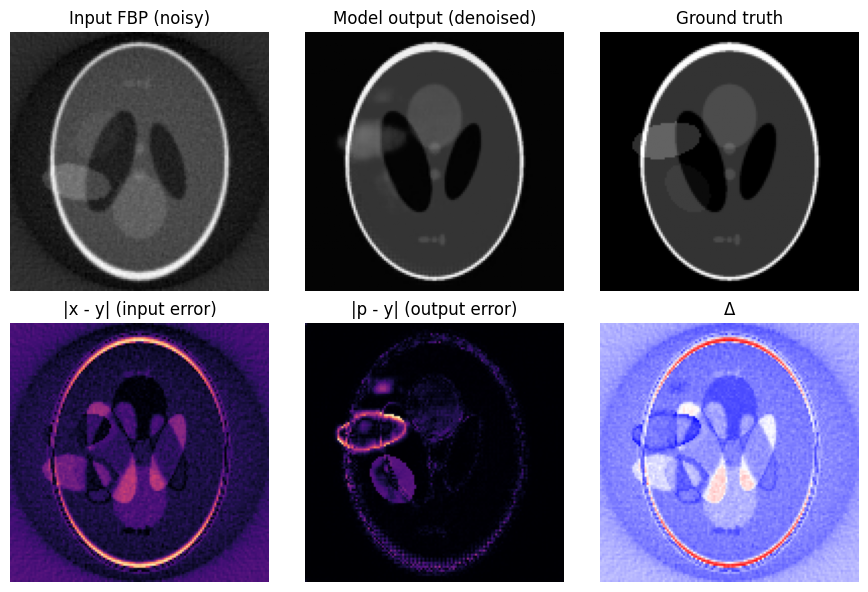

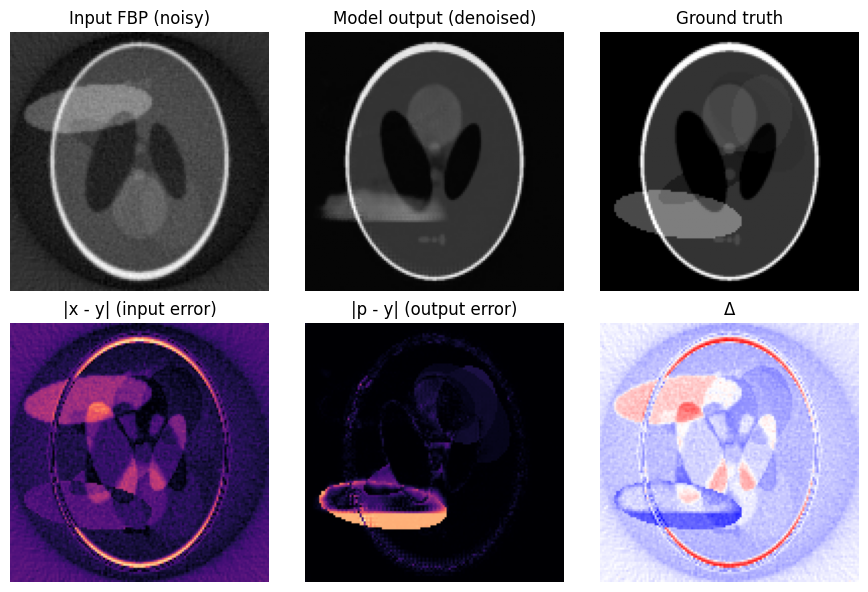

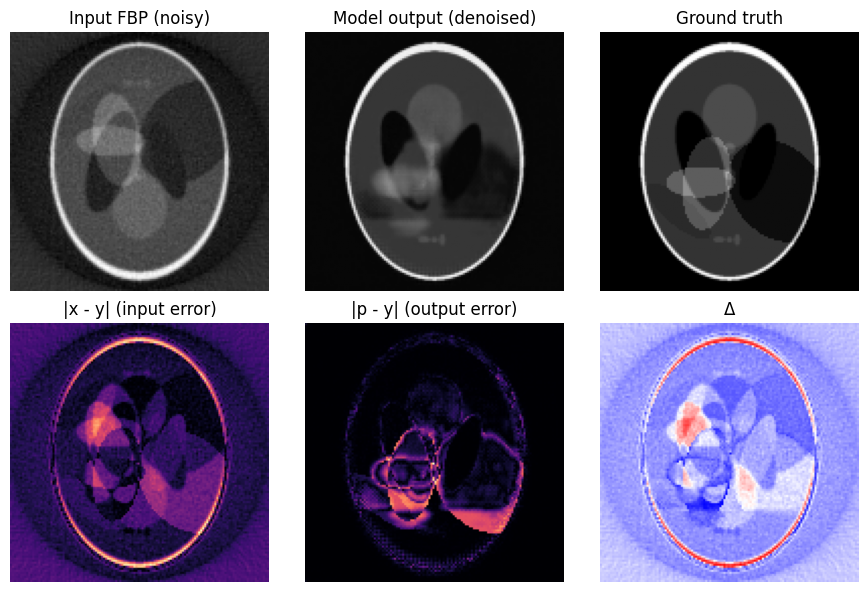

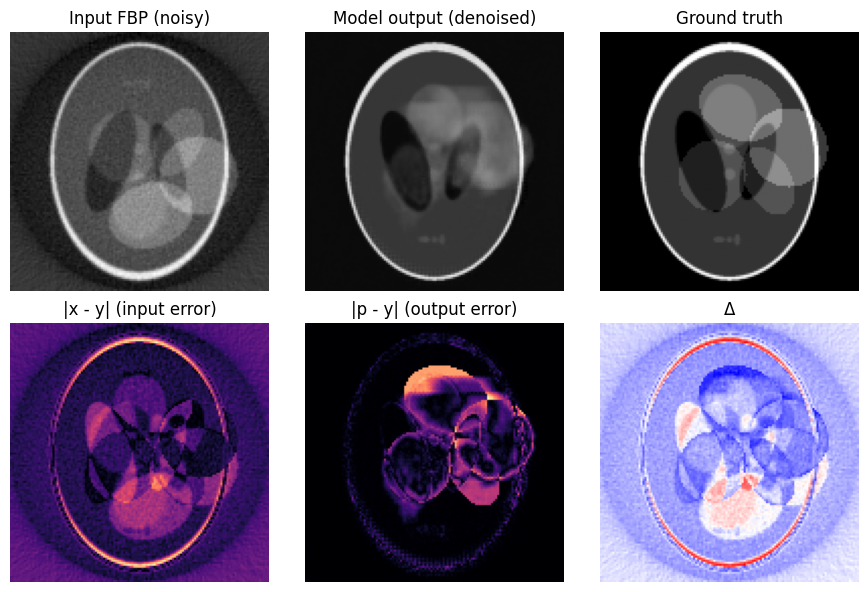

In [70]:
@torch.no_grad()
def show_qualitative(model, loader, n=4):
    model.eval(); shown=0
    for x,y in loader:
        x,y=x.to(device), y.to(device)
        pred=model(x)
        for i in range(x.size(0)):
            if shown>=n: return
            xi=x[i,0].cpu().numpy()
            yi=y[i,0].cpu().numpy()
            pi=pred[i,0].cpu().numpy()

            err_in  = np.abs(xi - yi)
            err_out = np.abs(pi - yi)
            delta   = err_in - err_out

            fig,axs=plt.subplots(2,3, figsize=(9,6))

            axs[0,0].imshow(xi, cmap='gray')
            axs[0,0].set_title("Input FBP (noisy)")
            axs[0,0].axis('off')

            axs[0,1].imshow(pi, cmap='gray')
            axs[0,1].set_title("Model output (denoised)")
            axs[0,1].axis('off')

            axs[0,2].imshow(yi, cmap='gray')
            axs[0,2].set_title("Ground truth")
            axs[0,2].axis('off')

            axs[1,0].imshow(err_in, cmap='magma')
            axs[1,0].set_title("|x - y| (input error)")
            axs[1,0].axis('off')

            axs[1,1].imshow(err_out, cmap='magma')
            axs[1,1].set_title("|p - y| (output error)")
            axs[1,1].axis('off')

            im = axs[1,2].imshow(delta, cmap='bwr')
            axs[1,2].set_title("Δ")
            axs[1,2].axis('off')

            plt.tight_layout()
            plt.show()
            shown+=1

show_qualitative(model, test_loader, n=4)


**Question:** In the red-blue difference map, which color indicates improvement and why? What does it mean when a region shows blue?

**Answer:**
1.  **Which color indicates improvement and why?**
    *   The color **Blue** typically indicates improvement (specifically in contexts like correcting myopia/nearsightedness).
    *   **Why?** In these maps, "cool" colors like blue usually represent a **decrease** in value (such as flattening of curvature or reduction in elevation). Since the goal of many refractive surgeries is to flatten the cornea to correct vision, a decrease in curvature (blue) signifies that the treatment was successful and an "improvement" has occurred.

2.  **What does it mean when a region shows blue?**
    *   When a region shows **Blue**, it means that the curvature or elevation in that specific area has **decreased** (flattened) compared to the baseline image.
    *   Conversely, **Red** regions would indicate an increase (steepening) of curvature.

---
**Summary:**
*   **Blue:** Flattening (Decrease in curvature/elevation) $\rightarrow$ Often implies improvement/treatment effect.
*   **Red:** Steepening (Increase in curvature/elevation).
*   **Green:** No significant change.